# 3. Routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/03_routing.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/03_routing.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You find routes on the turn graph of Monaco: between two roads, between two points, across modes, and with networkx and rustworkx.

| Method | Gives |
|---|---|
| `net.route` | the fastest route between two edges |
| `net.route_points` | the fastest route between two points (lon, lat) |
| `net.directions` | the turn-by-turn steps of a route |
| `net.route_multimodal_points` | a route that walks and drives |
| `net.to_networkx`, `net.to_rustworkx` | the turn graph as a graph object |

Each method calls the function of the same name: `net.route(...)` is `duckosm.route(net, ...)`.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:
    import duckosm
except ImportError:
    %pip install -q "duckosm[widget,networkx,rustworkx]" roadstyle
    import duckosm
print("duckosm", duckosm.__version__)

duckosm 0.8.0


## Build Monaco with three modes and the multimodal graph

The multimodal graph (`mm.*`) connects the modes at shared junctions. Only a config file turns it on.

In [2]:
area = duckosm.get("Monaco", out="data")    # the OSM file of Monaco and its boundary
# a config file: three modes and the multimodal graph
config = f"""name: monaco
output_path: data/monaco_mm.duckdb
source: {{type: pbf, pbf_path: {area.pbf}}}
boundary: {{path: {area.boundary}}}
modes: [driving, walking, cycling]
multimodal: {{enabled: true}}
"""
open("monaco.yaml", "w").write(config)
net = duckosm.build(config="monaco.yaml")
net.modes

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco_mm.duckdb

['driving', 'walking', 'cycling']

## Between two roads: `route`

A route goes from one edge to another edge. It obeys the turn restrictions of OSM.

In [3]:
q = "SELECT min(edge_id) AS edge_id FROM driving.edges WHERE name = ?"
start = int(net.sql(q, ["Boulevard du Larvotto"]).edge_id[0])    # one edge of each road
end = int(net.sql(q, ["Avenue Princesse Grace"]).edge_id[0])
r = net.route(start, end)    # the fastest route from edge to edge
print(f"{r['time_s']:.0f} s, {r['length_m']:.0f} m, {len(r['edges'])} edges")

114 s, 1513 m, 29 edges


## Between two points: `route_points`

The points are (lon, lat). The route starts and ends at the nearest road, and adds the walk to it. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

In [4]:
a, b = (7.4155, 43.7285), (7.4335, 43.7468)    # Fontvieille and Larvotto
drive = net.route_points(a, b)                 # by car
walk = net.route_points(a, b, mode="walking")  # on foot
print(f"driving: {drive['time_s'] / 60:.1f} min, {drive['length_m']:.0f} m")
print(f"walking: {walk['time_s'] / 60:.1f} min, {walk['length_m']:.0f} m")

driving: 3.8 min, 2939 m
walking: 36.4 min, 3030 m


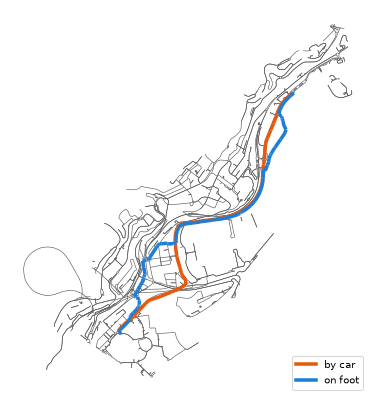

In [5]:
net.map(route={"by car": drive, "on foot": walk})    # the two routes as lines on the map

## Turn-by-turn steps: `directions`

In [6]:
for step in net.directions(drive):    # one step for each turn of the car route
    print(f"{step['length_m']:6.0f} m  {step['text']}")

    23 m  Head northwest on Avenue des Castelans
   179 m  At the roundabout, take the 1st exit onto Avenue Albert II
   189 m  At the roundabout, take the 3rd exit onto Avenue Albert II
   207 m  Continue onto Tunnel Rocher Palais
   129 m  Continue onto Tunnel Rocher Albert Ier
   120 m  Continue onto Tunnel Rocher Palais
   416 m  Continue onto Boulevard Albert 1er
   311 m  At the roundabout, take the 1st exit onto Avenue John F. Kennedy
   676 m  Continue onto Boulevard Louis II
   679 m  At the roundabout, take the 2nd exit onto Avenue Princesse Grace
     0 m  Arrive at your destination


## Across modes: `route_multimodal_points`

The route can walk to a car and drive. Each leg has its mode.

In [7]:
m = net.route_multimodal_points(a, b)    # the fastest route with any of the modes
print(f"{m['time_s'] / 60:.1f} min, {len(m['transfers'])} transfers")
for leg in m["legs"]:    # one leg for each mode
    print(f"  {leg['mode']:8} {len(leg['edges']):3} edges  {leg['time_s']:6.0f} s")

5.8 min, 2 transfers
  walking    1 edges       3 s
  driving   75 edges     220 s
  walking    1 edges       0 s


## As a graph: `to_networkx` and `to_rustworkx`

A node is an `edge_id`. An arc is a legal turn. The weight of an arc is the time in seconds of the edge before the turn. The two libraries give the same shortest time, and the same path as `route`.

In [8]:
import networkx as nx

g = net.to_networkx()    # the turn graph of the driving network
print(g.number_of_nodes(), "nodes,", g.number_of_edges(), "turns")
print("time:", round(nx.shortest_path_length(g, start, end, weight="weight"), 1), "s")
print("the same path as route:", nx.shortest_path(g, start, end, weight="weight") == r["edges"])

2840 nodes, 5082 turns
time: 113.2 s
the same path as route: True


In [9]:
import rustworkx as rx

h = net.to_rustworkx()    # the same graph in rustworkx
ix = h.attrs["index"]     # the node index of each edge_id
t = rx.dijkstra_shortest_path_lengths(h, ix[start], edge_cost_fn=float, goal=ix[end])[ix[end]]
print(h.num_nodes(), "nodes,", h.num_edges(), "turns, time:", round(t, 1), "s")

2840 nodes, 5082 turns, time: 113.2 s


The graph time does not include the time of the last edge, so it is less than the time of `route`.